# Retail Sales Analysis
### CodeNova Batch 01 - Task 1

**Dataset:** fictional retail orders across four regions of India, January 2024-December 2025. All monetary values are INR. This is an educational analysis of synthetic data, not evidence about actual markets.

**Questions:** Which categories drive sales and margins? How do monthly, quarterly and seasonal results differ? Where is revenue concentrated? Are the conclusions sensitive to data cleaning and bulk purchases?

The companion Task 2 project generated and cleaned the data. The standalone copies bundled here let this notebook run independently. Prices/costs are fixed in the synthetic catalog; one row is one completed order for one product, with one or more units. No refunds, taxes, shipping, operating expenses or customer demographics are modeled.

In [1]:
from pathlib import Path
import hashlib, json, sys
import pandas as pd
from IPython.display import display, Image, Markdown
from analysis import run, ROOT
pd.set_option('display.max_columns', 12)
df, tables, metrics, checks, sensitivity, exclusion = run()
print('Python:', sys.version.split()[0])
print('Dataset SHA-256:', hashlib.sha256((ROOT/'data/sales_clean.csv').read_bytes()).hexdigest())
print(f'{len(df):,} orders; {df.order_date.min().date()} to {df.order_date.max().date()}')
display(df.head())

Python: 3.12.3
Dataset SHA-256: 3496b1f75261f24ab1e302fb80b297f02ff89bfa7647a9456df515844a04c3ca
3,129 orders; 2024-01-01 to 2025-12-31


,order_id,order_date,product_id,category,region,quantity,...,cost_paise,profit_paise,month,quarter,year,season
0,ORD000001,2024-01-28,P03,Electronics,North,1,...,129900,60005,2024-01,2024Q1,2024,Winter
1,ORD000002,2024-01-22,P04,Home,South,2,...,149800,150000,2024-01,2024Q1,2024,Winter
2,ORD000003,2024-01-08,P03,Electronics,South,1,...,129900,70000,2024-01,2024Q1,2024,Winter
3,ORD000004,2024-01-05,P05,Home,South,1,...,44900,45000,2024-01,2024Q1,2024,Winter
4,ORD000005,2024-01-21,P06,Home,North,2,...,119800,108010,2024-01,2024Q1,2024,Winter


## 1. Validate the analysis input
The cleaner handles missing fields, duplicate/conflicting IDs, invalid dates and types, reference-based recovery, and IQR flags. Here we verify the analysis contract again. `Unspecified` is an explicit unknown region; no orders disappear from geographic aggregation.

In [2]:
assert df.order_id.is_unique
assert df.isna().sum().sum() == 0
assert df.order_date.between('2024-01-01', '2025-12-31').all()
assert df.month.nunique() == 24
assert df.discount_pct.between(0,100).all()
display(pd.DataFrame({'dtype':df.dtypes.astype(str), 'nulls':df.isna().sum()}))
display(df[['quantity','discount_pct','gross_paise','net_paise','profit_paise']].describe())

,dtype,nulls
order_id,object,0
order_date,datetime64[ns],0
product_id,object,0
category,object,0
region,object,0
quantity,int64,0
unit_price,object,0
unit_cost,object,0
discount_pct,int64,0
source_row,int64,0


,quantity,discount_pct,gross_paise,net_paise,profit_paise
count,3129.000000,3129.000000,3.129000e+03,3.129000e+03,3.129000e+03
mean,1.904442,7.277085,2.579559e+05,2.389386e+05,8.886981e+04
std,1.944764,5.600191,4.076950e+05,3.772018e+05,1.207374e+05
min,1.000000,0.000000,1.490000e+04,1.266500e+04,5.265000e+03
25%,1.000000,0.000000,5.970000e+04,5.671500e+04,2.453000e+04
50%,1.000000,5.000000,1.398000e+05,1.299000e+05,6.001500e+04
75%,2.000000,10.000000,2.999000e+05,2.849050e+05,1.170200e+05
max,18.000000,15.000000,8.098200e+06,7.693290e+06,2.295090e+06


## 2. Metric definitions
- **Total gross revenue:** sum(quantity x unit price), before discounts.
- **Net revenue:** gross revenue minus discounts. Discounts round half-up to the nearest paise per order.
- **Gross profit:** net revenue minus quantity x unit cost. This is not operating/net profit.
- **Gross profit margin:** total gross profit / total net revenue x 100. Do not average row margins.
- **Average order value (AOV):** total net revenue / distinct completed orders.
- **Unit volume:** total quantity.

All monetary aggregations use integer paise. INR conversion occurs only for display. One lakh = INR 100,000.

In [3]:
kpis = pd.DataFrame([
    ('Gross revenue (INR)', metrics['gross_paise']/100),
    ('Discounts (INR)', metrics['discount_paise']/100),
    ('Net revenue (INR)', metrics['net_paise']/100),
    ('Cost of goods (INR)', metrics['cost_paise']/100),
    ('Gross profit (INR)', metrics['profit_paise']/100),
    ('Gross margin (%)', metrics['margin_pct']),
    ('Average order value (INR)', metrics['aov_inr']),
    ('Orders', metrics['orders']), ('Units', metrics['units'])], columns=['Metric','Value'])
display(kpis.style.format({'Value':'{:,.2f}'}))

,Metric,Value
0,Gross revenue (INR),"8,071,441.00"
1,Discounts (INR),"595,053.50"
2,Net revenue (INR),"7,476,387.50"
3,Cost of goods (INR),"4,695,651.00"
4,Gross profit (INR),"2,780,736.50"
5,Gross margin (%),37.19
6,Average order value (INR),"2,389.39"
7,Orders,"3,129.00"
8,Units,"5,959.00"


## 3. Monthly and quarterly performance
Compare two complete calendar years; month-over-month changes can be noisy. Year-over-year comparisons control for calendar month but still do not establish causality. The generator deliberately increases fourth-quarter order volumes and 2025 order counts.

,orders,units,net_revenue_inr,margin_pct,mom_pct,yoy_pct
month,,,,,,
2024-01,75,137,176559.80,39.07,NaN,NaN
2024-02,105,207,242983.10,39.48,37.62,NaN
2024-03,102,183,232851.65,37.59,-4.17,NaN
2024-04,110,191,218725.20,36.63,-6.07,NaN
2024-05,110,174,232677.85,36.47,6.38,NaN
2024-06,110,210,268844.75,36.59,15.54,NaN
2024-07,110,212,254705.65,38.52,-5.26,NaN
2024-08,110,252,305920.80,37.97,20.11,NaN
2024-09,110,221,234052.75,38.34,-23.49,NaN


,gross_paise,net_paise,cost_paise,profit_paise,discount_paise,units,orders,margin_pct,aov_inr
quarter,,,,,,,,,
2024Q1,70287300,65239455,39995800,25243655,5047845,527,282,38.693847,2313.455851
2024Q2,77292500,72024780,45691000,26333780,5267720,575,330,36.562111,2182.569091
2024Q3,85881500,79467920,49065500,30402420,6413580,685,330,38.257475,2408.118788
2024Q4,130206700,120974015,76780700,44193315,9232685,933,510,36.531246,2372.039510
2025Q1,91505300,84395460,52974800,31420660,7109840,647,369,37.230273,2287.139837
2025Q2,98789900,92243830,57549400,34694430,6546070,751,369,37.611654,2499.832791
2025Q3,104586600,96183600,61905100,34278500,8403000,734,369,35.638612,2606.601626
2025Q4,148594300,137109690,85602800,51506890,11484610,1107,570,37.566192,2405.433158


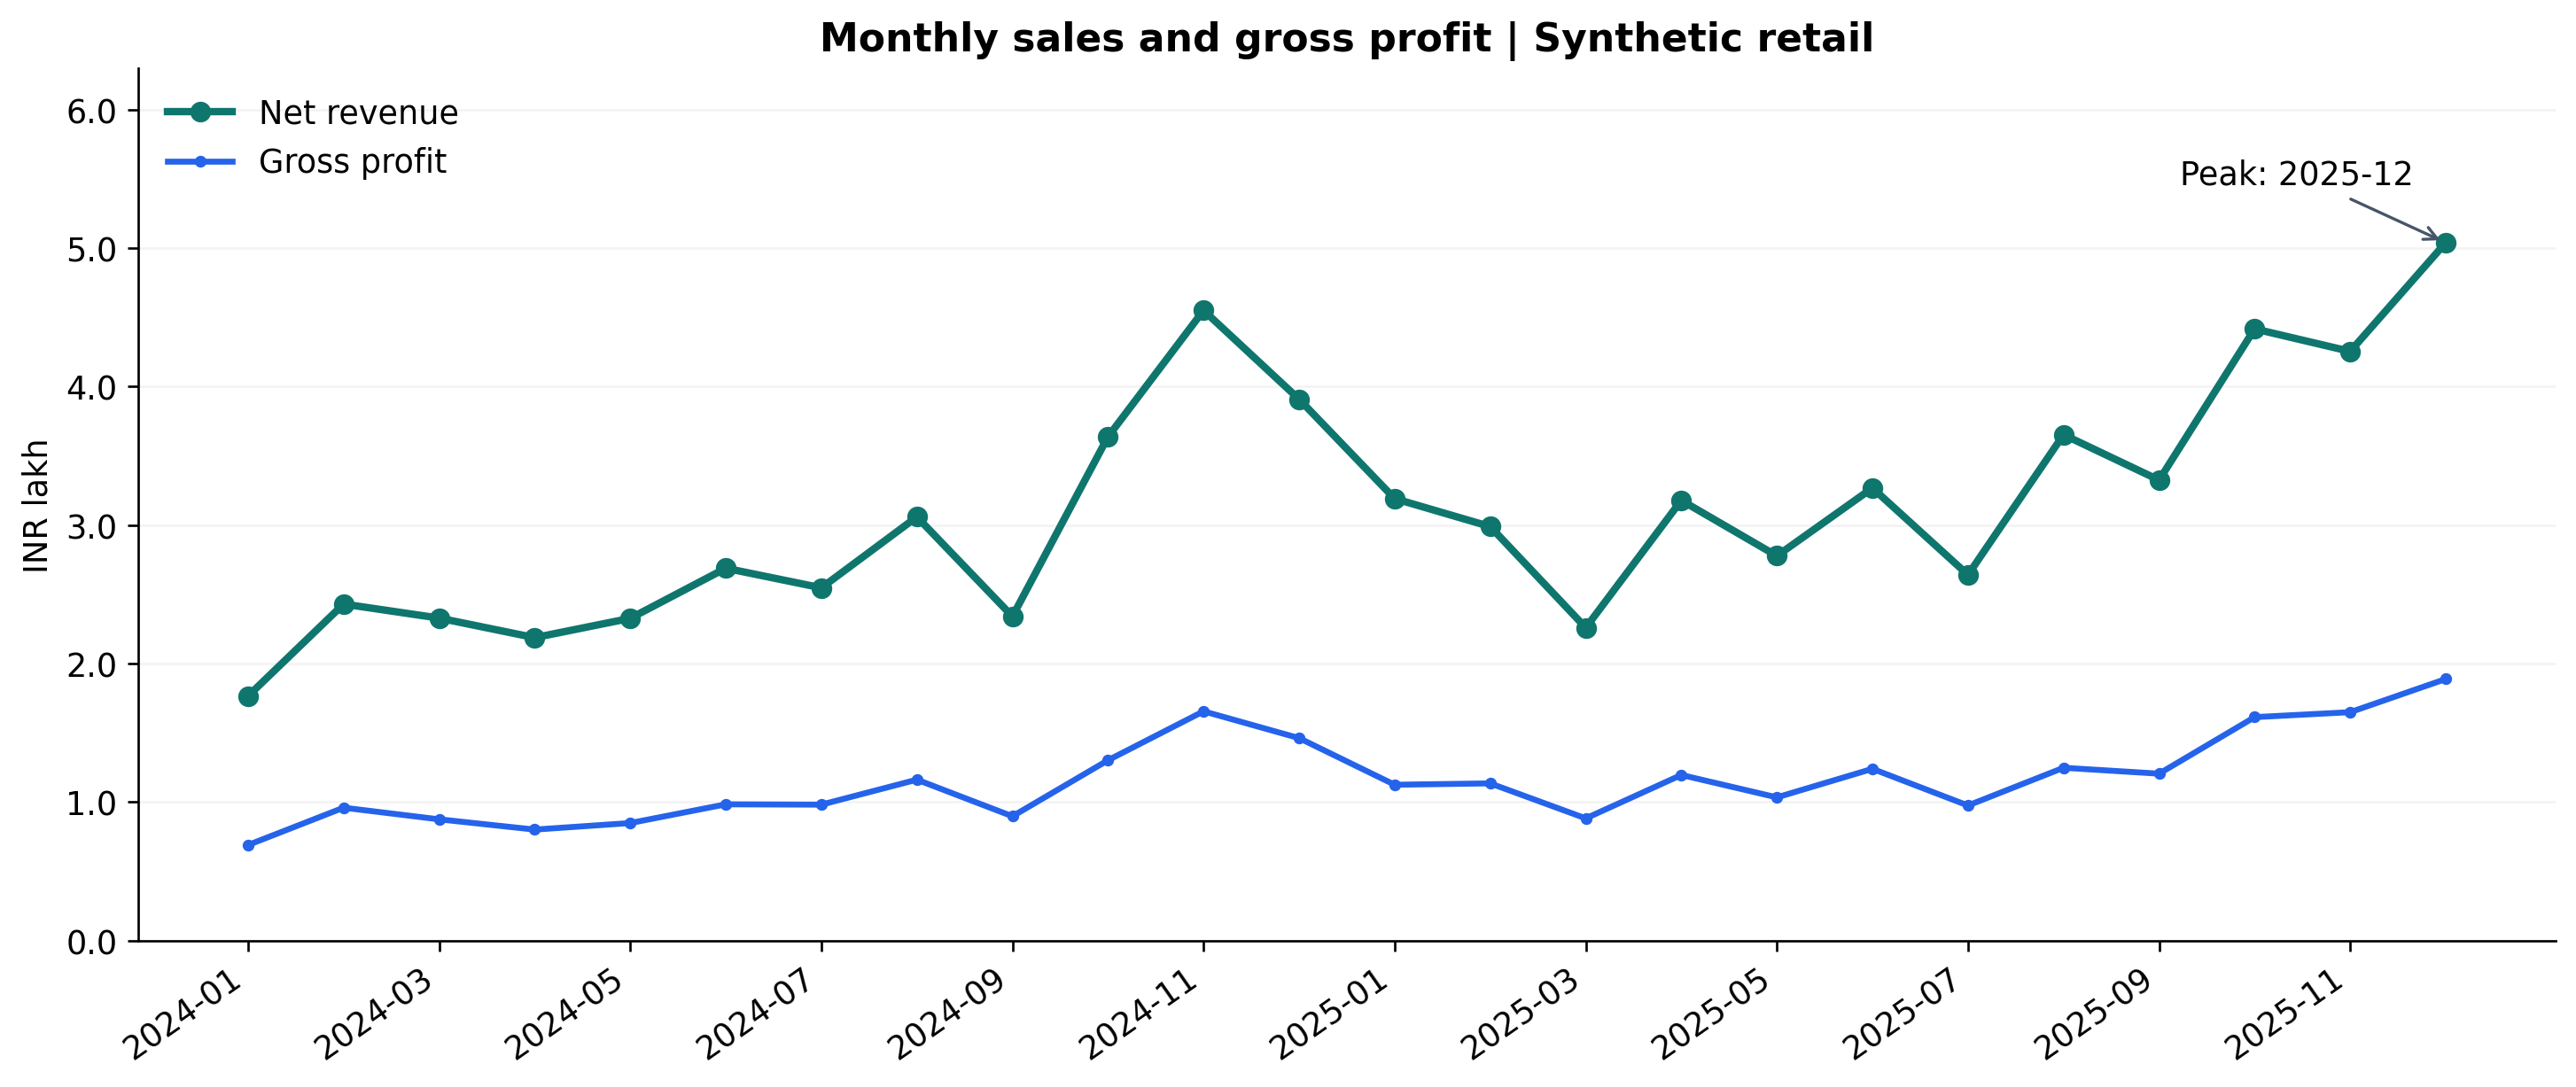

In [4]:
monthly=tables['month'].copy()
monthly['net_revenue_inr']=monthly.net_paise/100
monthly['mom_pct']=monthly.net_paise.pct_change()*100
monthly['yoy_pct']=monthly.net_paise.pct_change(12)*100
display(monthly[['orders','units','net_revenue_inr','margin_pct','mom_pct','yoy_pct']].round(2))
display(tables['quarter'])
display(Image(filename=str(ROOT/'output/charts/01_monthly_trends.png')))

## 4. Seasonal patterns
Use explicitly defined calendar buckets: winter (December-February), pre-monsoon (March-May), monsoon (June-September), post-monsoon (October-November). These labels are an analytical convenience, not a regional climate claim. Buckets have different lengths, so compare average revenue per observed month as well as totals. December belongs to winter even though it is in Q4. Two years cannot establish robust seasonal effects.

,orders,units,net_paise,observed_months,net_inr_per_month
season,,,,,
Monsoon,932,1885,235216565,8,294020.71
Post-monsoon,720,1297,168600795,4,421501.99
Pre-monsoon,691,1231,150579910,6,250966.52
Winter,786,1546,193241480,6,322069.13


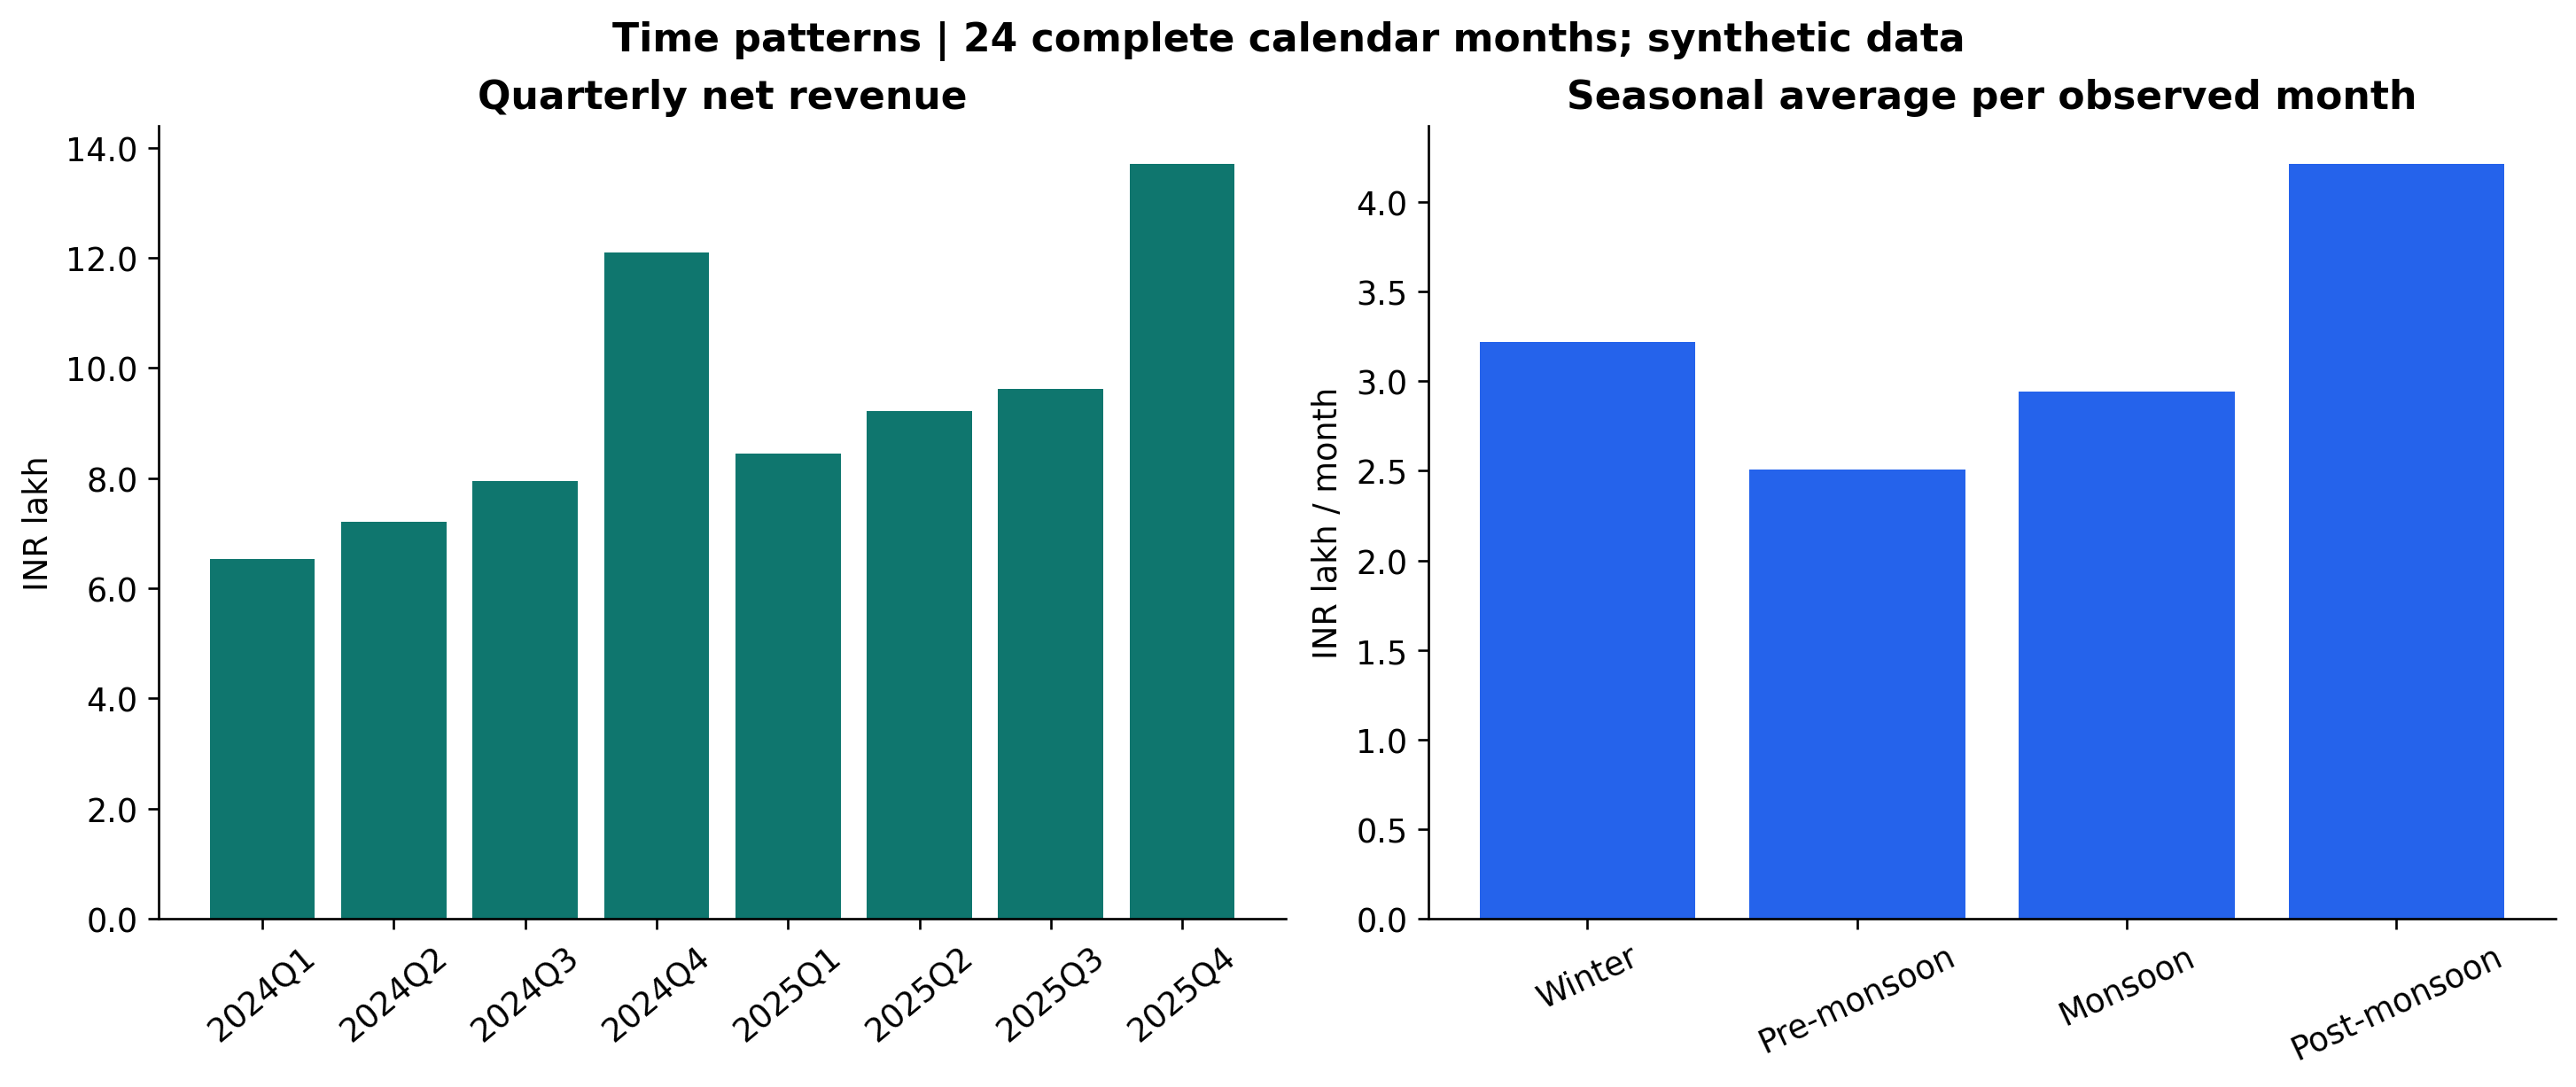

In [5]:
season=tables['season'].copy()
season['observed_months']=df.groupby('season').month.nunique()
season['net_inr_per_month']=season.net_paise/100/season.observed_months
display(season[['orders','units','net_paise','observed_months','net_inr_per_month']].round(2))
display(Image(filename=str(ROOT/'output/charts/02_quarterly_seasonal.png')))

## 5. Category and product performance
Evaluate revenue, units and margin separately: a high-price category can lead revenue without leading volume. Category margins are weighted ratios of totals. Price/cost assumptions were designed into the synthetic catalog, so they are not discovered real-world economics.

,gross_paise,net_paise,cost_paise,profit_paise,discount_paise,units,orders,margin_pct,aov_inr
category,,,,,,,,,
Electronics,473649400,438238130,311734400,126503730,35411270,1506,789,28.87,5554.35
Home,180988700,168294245,90418700,77875545,12694455,1513,800,46.27,2103.68
Fashion,118512900,109534440,50488900,59045540,8978460,1471,754,53.91,1452.71
Stationery,33993100,31571935,16923100,14648835,2421165,1469,786,46.40,401.68


,gross_paise,net_paise,cost_paise,profit_paise,discount_paise,units,orders,margin_pct,aov_inr,product_name,category
product_id,,,,,,,,,,,
P02,234847800,217144235,156547800,60596435,17703565,522,269,27.91,8072.28,Speaker,Electronics
P01,126257900,116886025,82052900,34833125,9371875,421,247,29.80,4732.23,Headphones,Electronics
P03,112543700,104207870,73133700,31074170,8335830,563,273,29.82,3817.14,Keyboard,Electronics
P06,70621100,65579305,35281100,30298205,5041795,589,293,46.20,2238.20,Cushion Set,Home
P04,68204500,63325255,34079500,29245755,4879245,455,263,46.18,2407.80,Lamp,Home
P08,63391200,58584900,28499200,30085700,4806300,488,258,51.35,2270.73,Backpack,Fashion
P05,42163100,39389685,21058100,18331585,2773415,469,244,46.54,1614.33,Storage Set,Home
P07,37047000,34149645,14787000,19362645,2897355,530,239,56.70,1428.86,T-shirt,Fashion
P09,18074700,16799895,7202700,9597195,1274805,453,257,57.13,653.69,Cap,Fashion


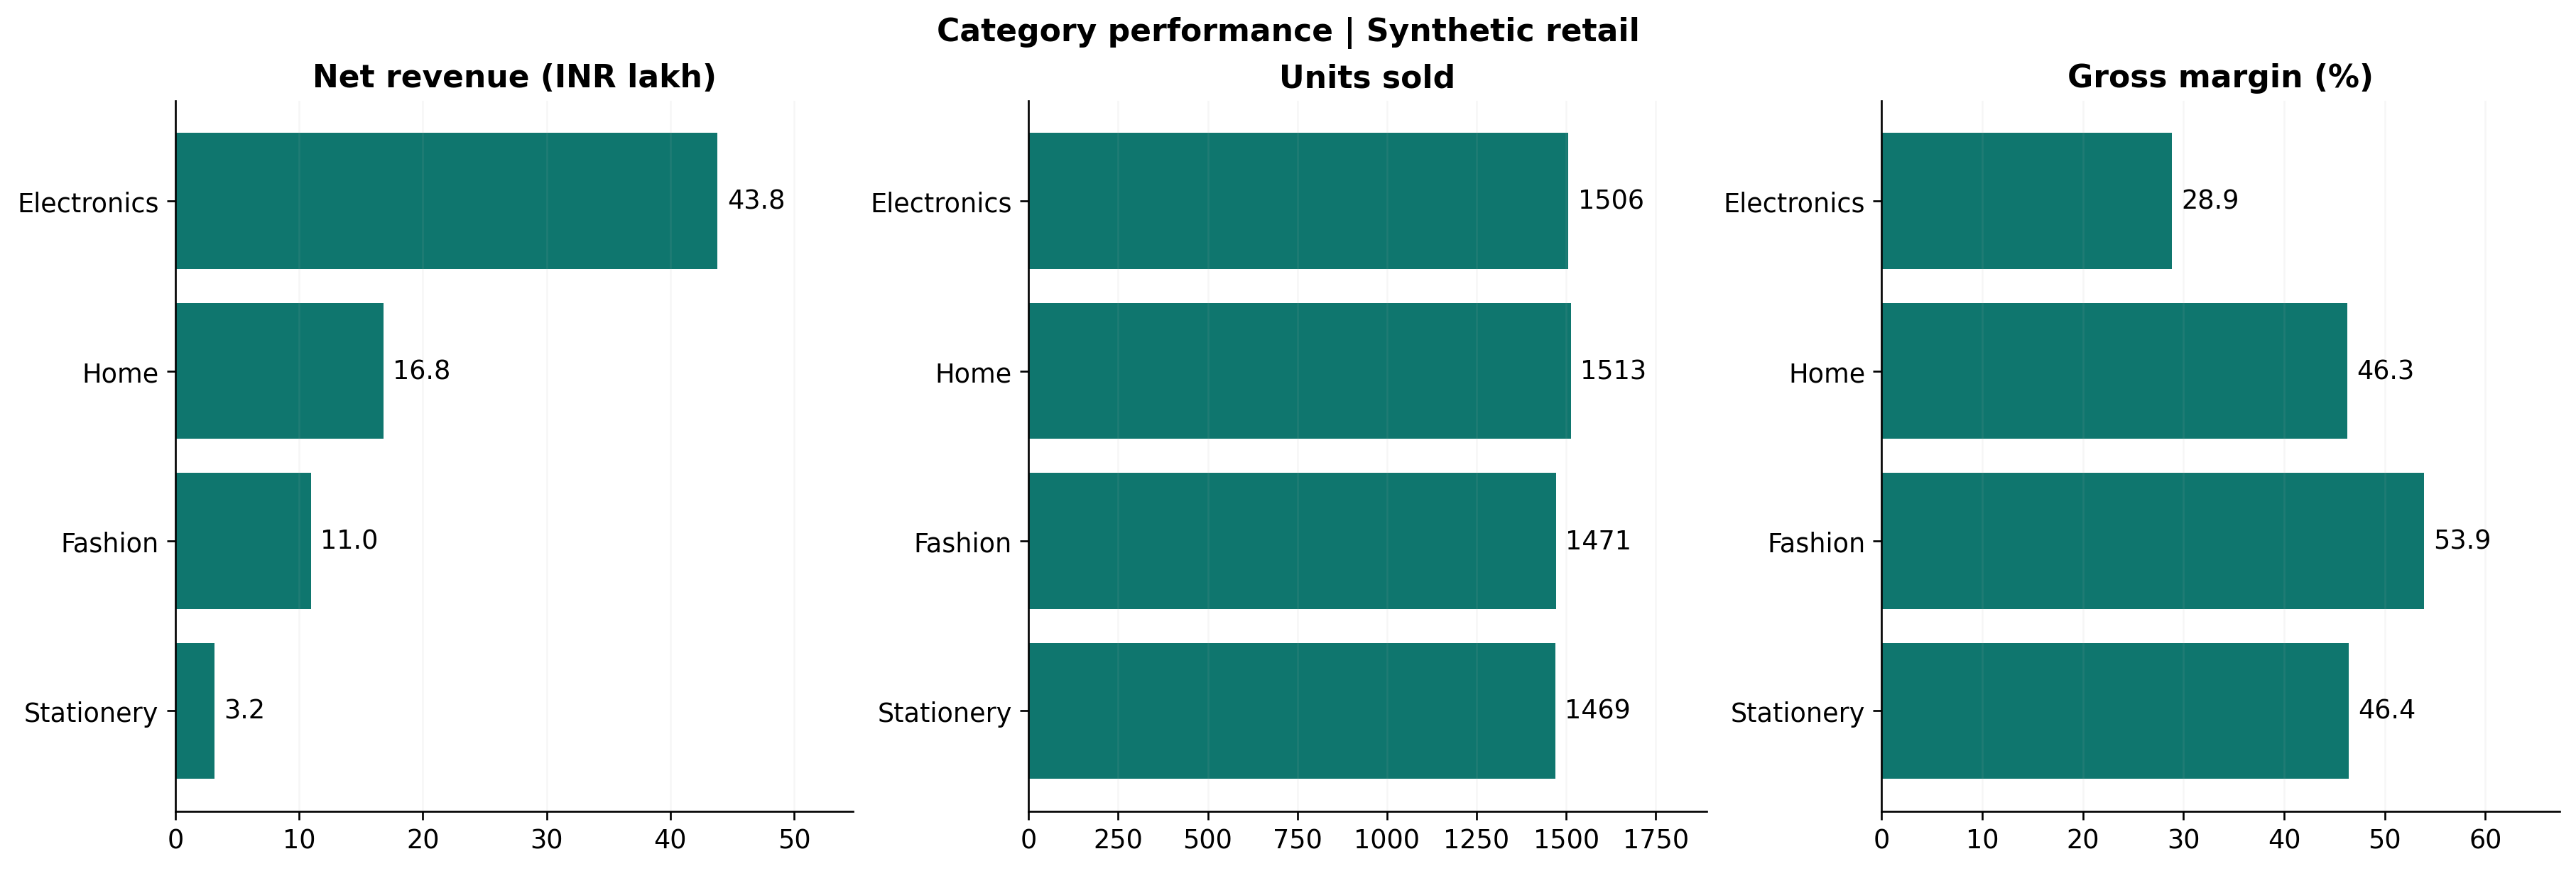

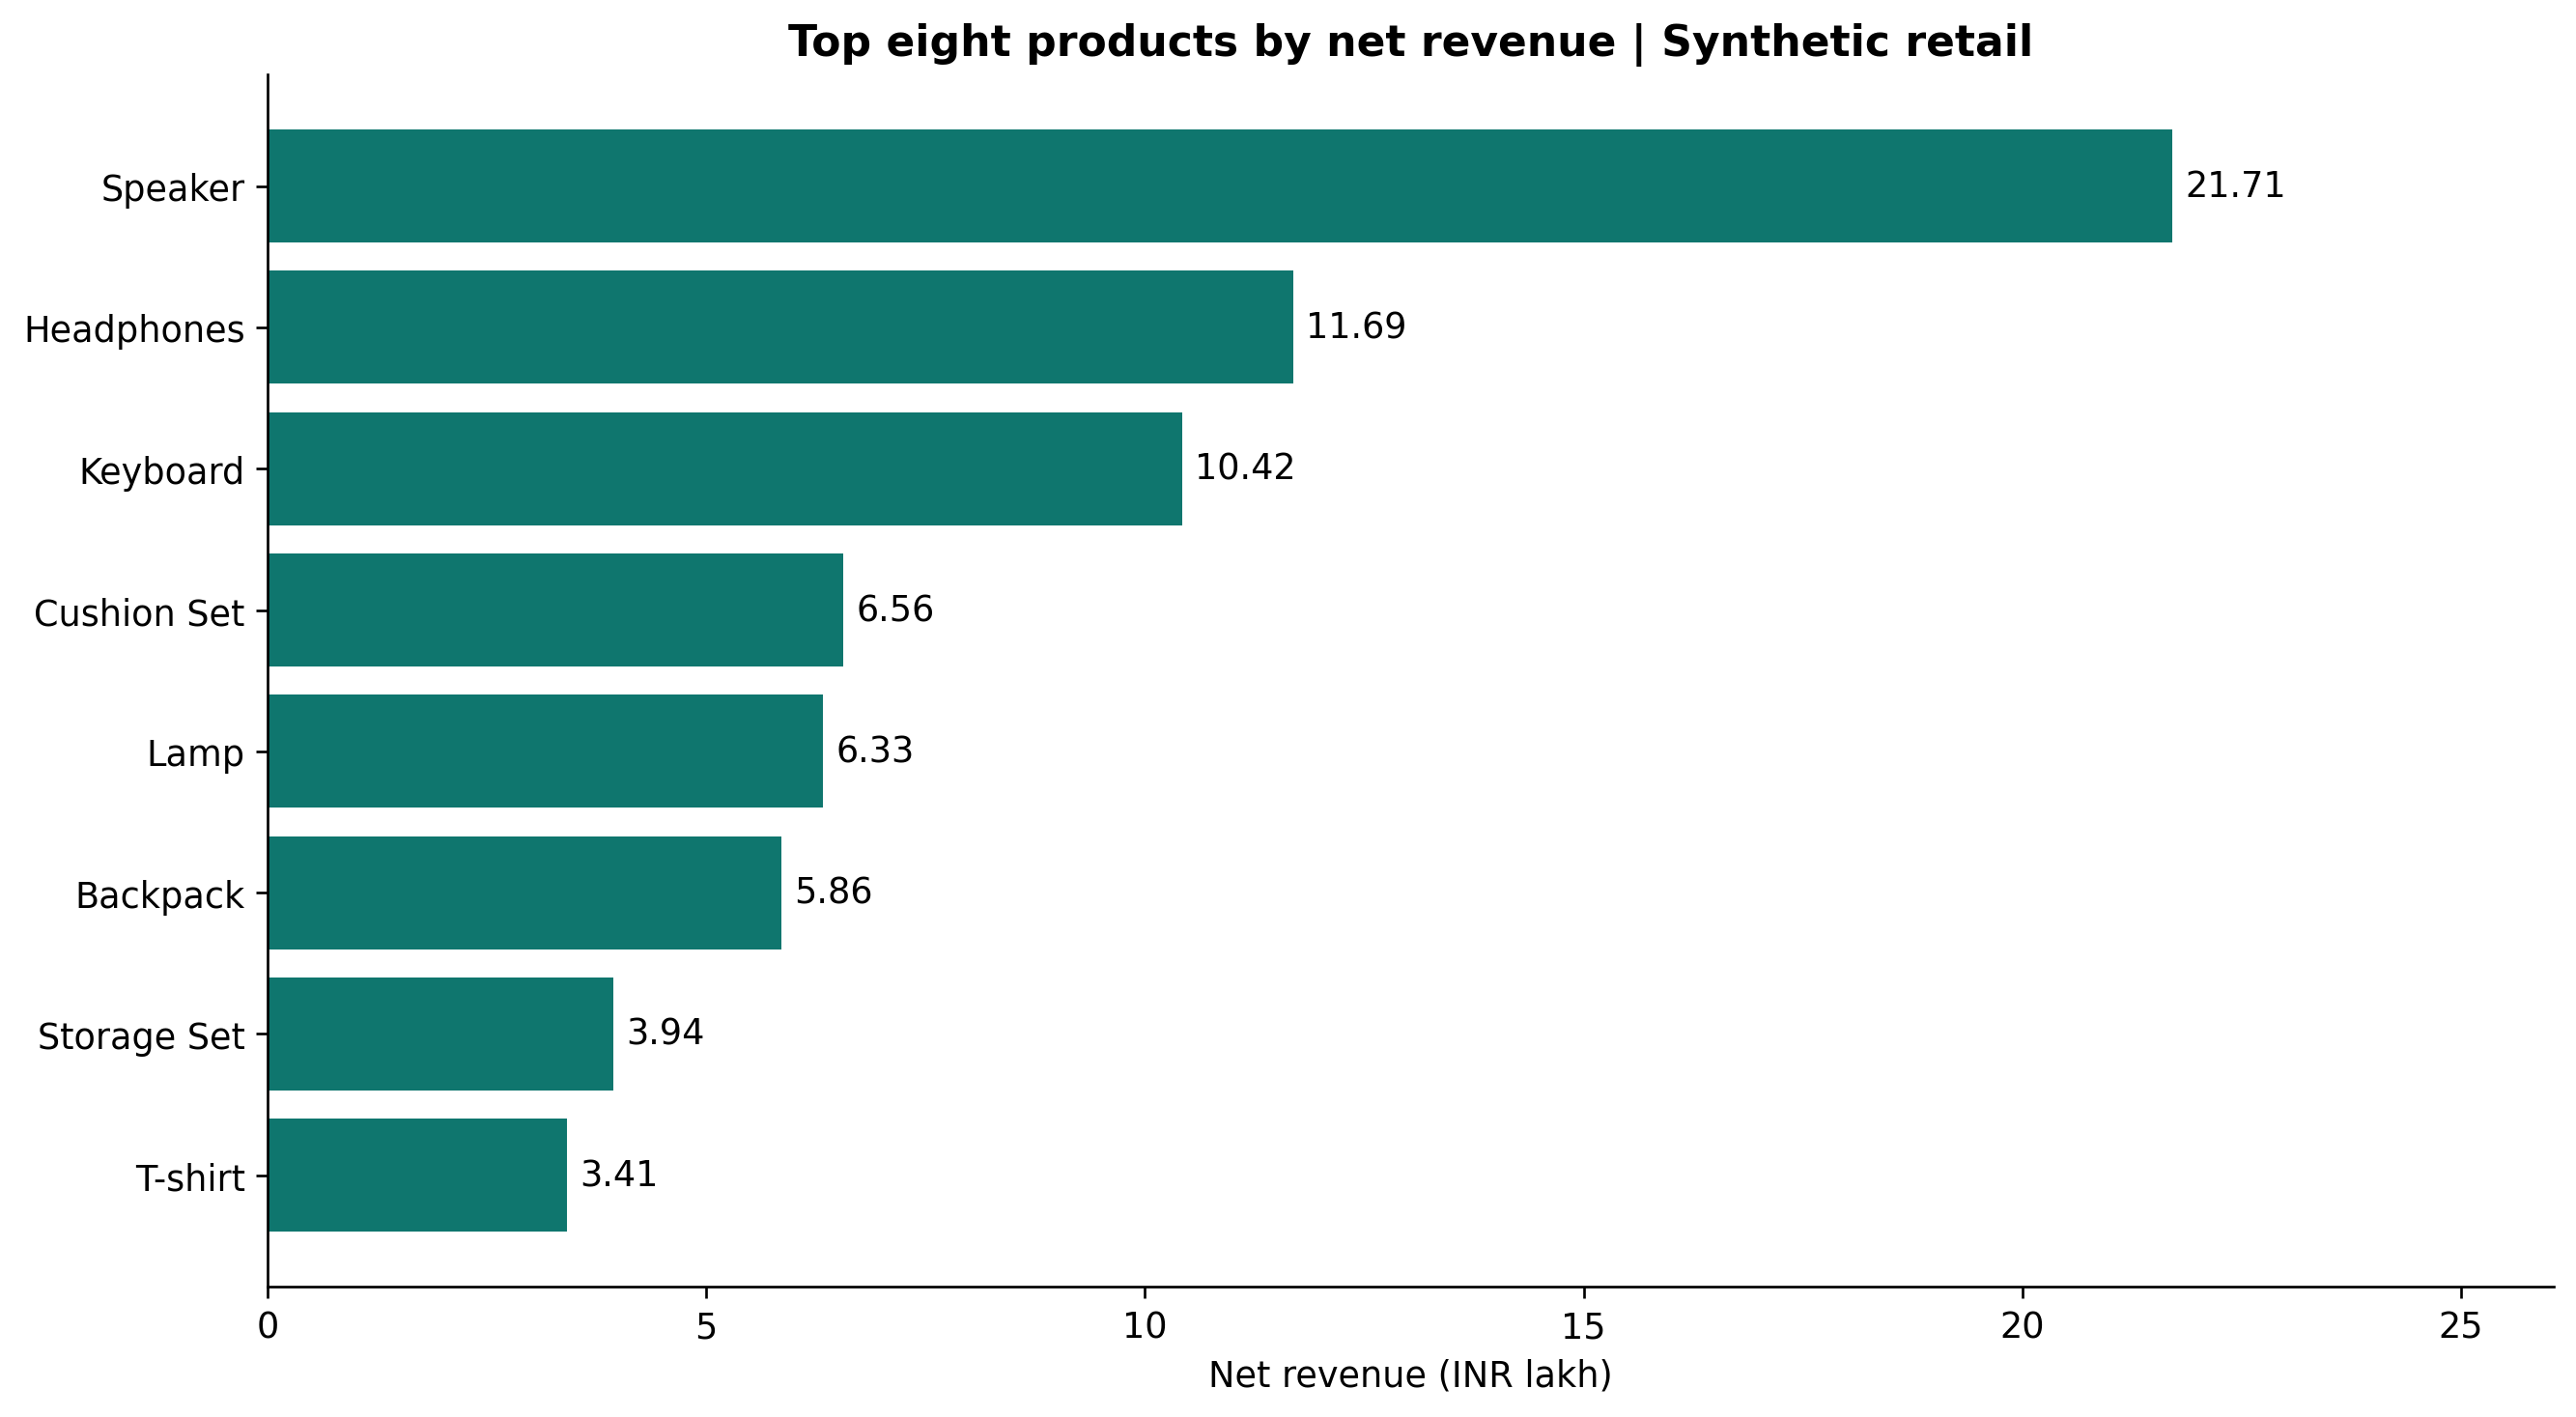

In [6]:
display(tables['category'].sort_values('net_paise',ascending=False).round(2))
catalog=pd.read_csv(ROOT/'data/product_catalog.csv').set_index('product_id')
display(tables['product_id'].join(catalog[['product_name','category']]).sort_values('net_paise',ascending=False).round(2))
display(Image(filename=str(ROOT/'output/charts/03_category_performance.png')))
display(Image(filename=str(ROOT/'output/charts/05_product_leaders.png')))

## 6. Regional sales distribution
This fulfills the geographic-distribution requirement. No demographic inference is attempted. Shares include unknown regions, and a region's share is not adjusted for population, store count or customer exposure.

,gross_paise,net_paise,cost_paise,profit_paise,discount_paise,units,orders,margin_pct,aov_inr,net_share_pct
region,,,,,,,,,,
East,129533700,119771855,76375200,43396655,9761845,913,461,36.23,2598.09,16.02
North,179803400,167311405,103380900,63930505,12491995,1366,749,38.21,2233.80,22.38
South,307382100,284925370,181113100,103812270,22456730,2129,1130,36.43,2521.46,38.11
Unspecified,2177800,2021980,1143300,878680,155820,22,15,43.46,1347.99,0.27
West,188247100,173608140,107552600,66055540,14638960,1529,774,38.05,2243.00,23.22


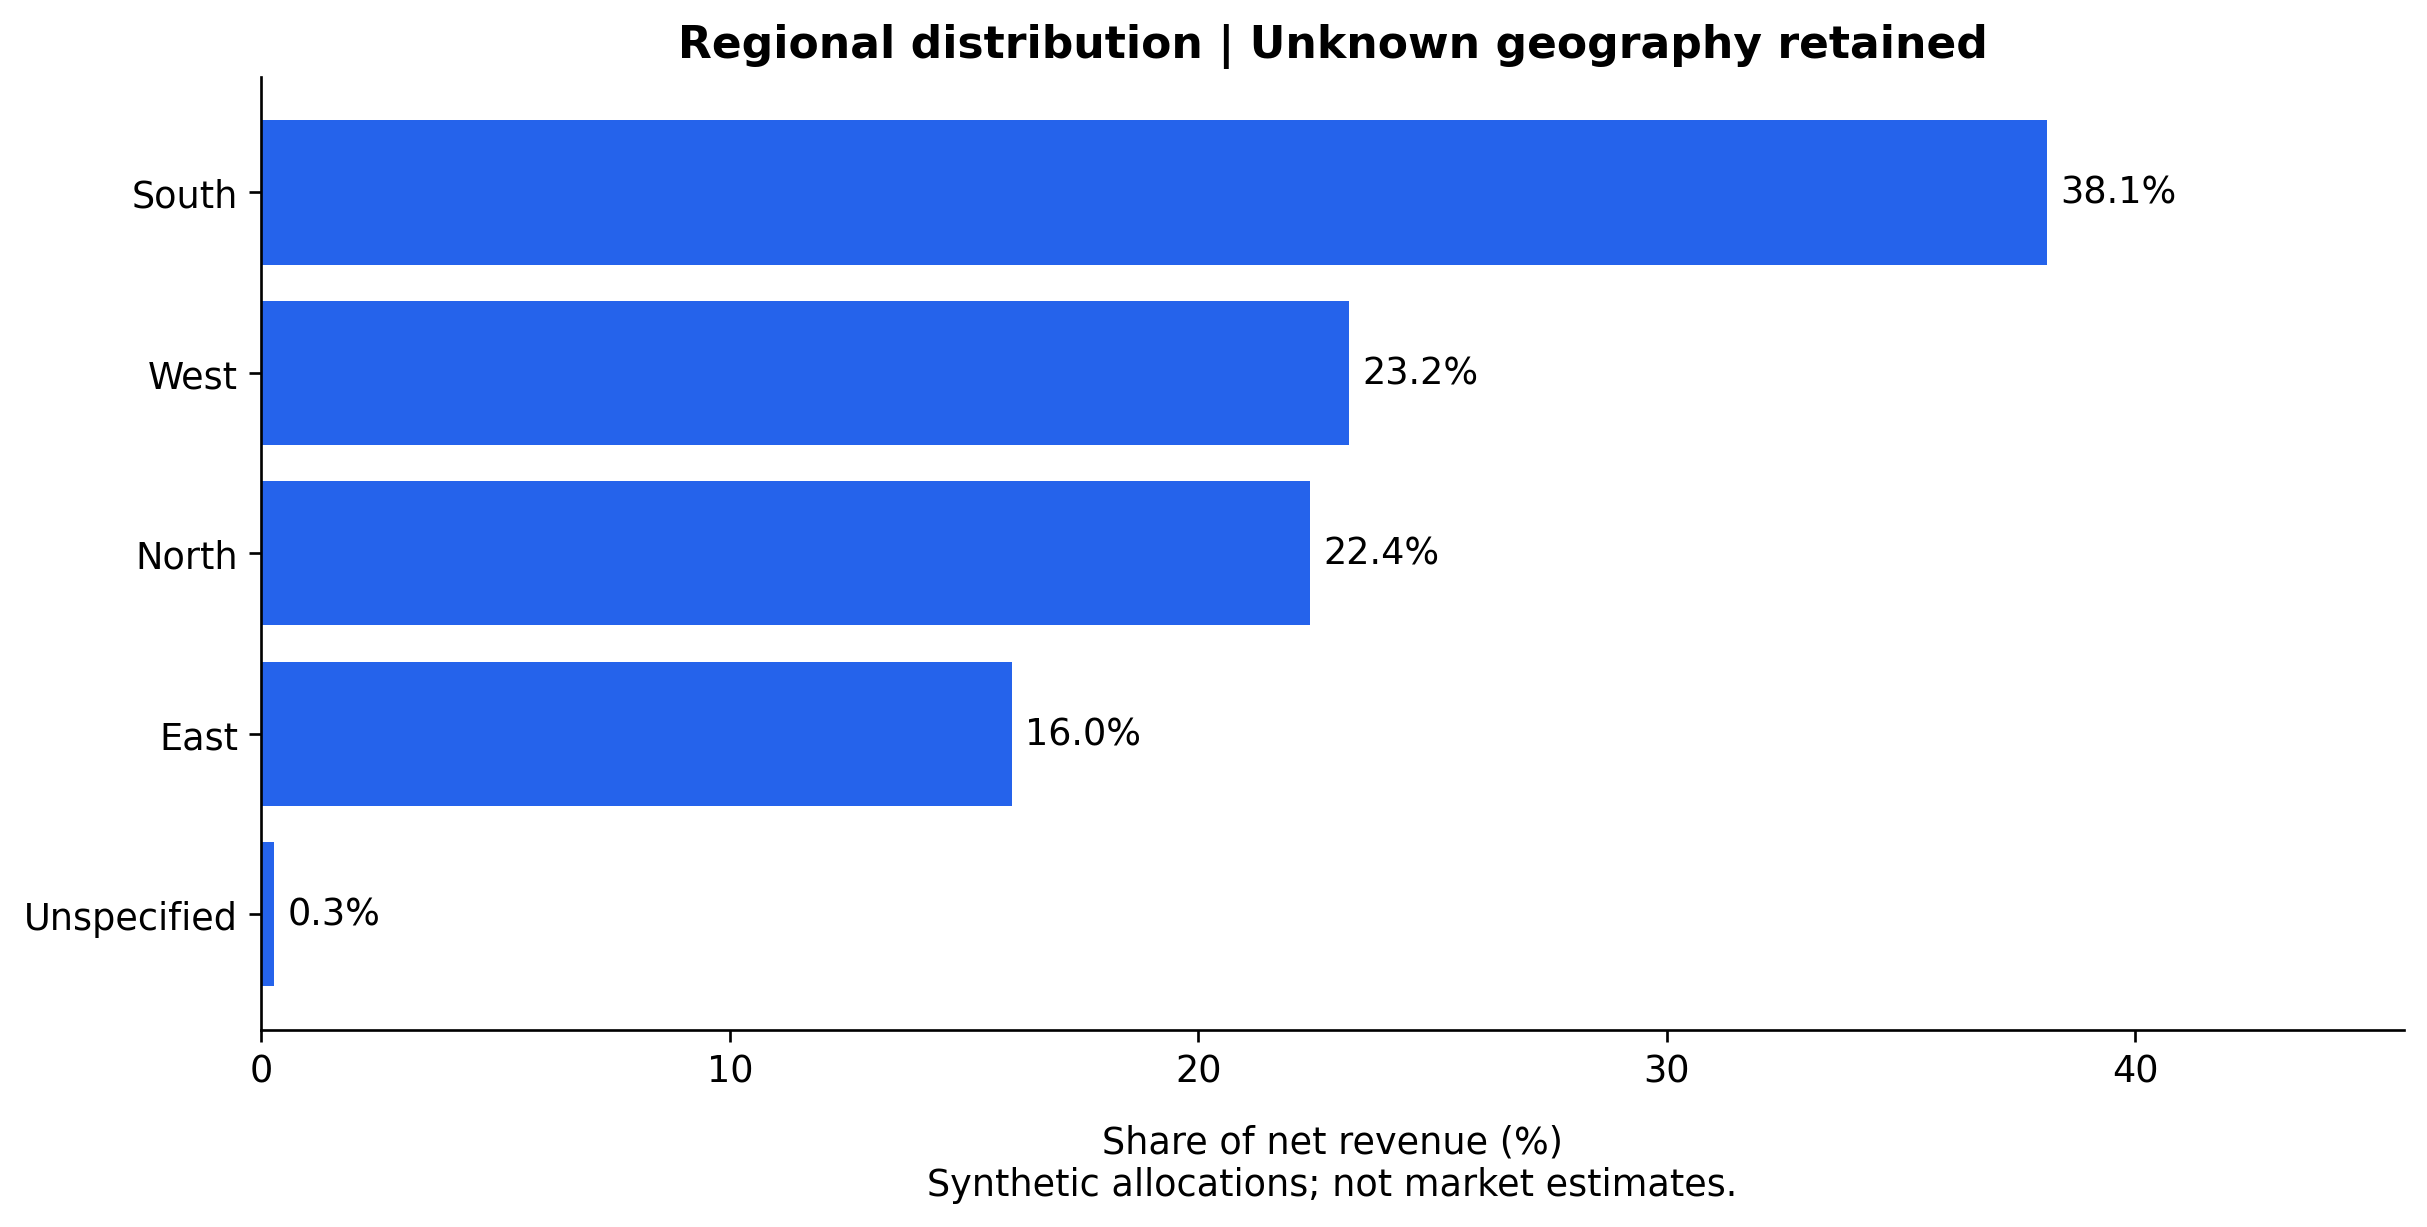

In [7]:
regional=tables['region'].copy()
regional['net_share_pct']=100*regional.net_paise/regional.net_paise.sum()
display(regional.round(2))
display(Image(filename=str(ROOT/'output/charts/04_regional_distribution.png')))

## 7. Reconcile every financial aggregation
All seven grouped dimensions must exactly reproduce five monetary totals, units and order counts. Every transaction has one category, product, region, month, quarter, year and season. These are additive partitions in this single-product-order dataset. Real multi-line orders would require special treatment of cross-category order counts.

In [8]:
display(checks)
print(f'{len(checks)} exact reconciliation checks passed: {checks.passed.all()}')
assert metrics['gross_paise']-metrics['discount_paise']==metrics['net_paise']
assert metrics['net_paise']-metrics['cost_paise']==metrics['profit_paise']

49 exact reconciliation checks passed: True


,dimension,metric,expected,observed,passed
0,month,gross_paise,807144100,807144100,True
1,month,net_paise,747638750,747638750,True
2,month,cost_paise,469565100,469565100,True
3,month,profit_paise,278073650,278073650,True
4,month,discount_paise,59505350,59505350,True
5,month,units,5959,5959,True
6,month,orders,3129,3129,True
7,quarter,gross_paise,807144100,807144100,True
8,quarter,net_paise,747638750,747638750,True
9,quarter,cost_paise,469565100,469565100,True


## 8. Sensitivity and limitations
Quantity outliers are retained because bulk orders can be legitimate. The exclusion scenario is a sensitivity test, not a recommendation to delete them. Also examine unique source IDs absent after cleaning: duplicate rows do not count as lost business. Blank IDs cannot be assigned to a unique order, and unparseable dates appear under `NaT`. Defects were injected into early 2024 rows, so year-over-year growth is partly affected by cleaning losses.

In [9]:
display(sensitivity.round(2))
print(f"Flagged orders: {metrics['outlier_orders']}; share of net revenue: {metrics['outlier_net_share_pct']:.2f}%")
display(exclusion.round(2))

Flagged orders: 189; share of net revenue: 20.07%


,scope,orders,net_inr,gross_profit_inr,aov_inr
0,All retained orders,3129,7476387.5,2780736.5,2389.39
1,Excluding flagged orders (sensitivity only),2940,5975602.0,2211591.0,2032.52


,identifiable_source_orders,excluded_orders,exclusion_pct
quarter,,,
2024Q1,320,38,11.88
2024Q2,330,0,0.00
2024Q3,330,0,0.00
2024Q4,510,0,0.00
2025Q1,369,0,0.00
2025Q2,369,0,0.00
2025Q3,369,0,0.00
2025Q4,570,0,0.00
NaT,5,5,100.00


## 9. Executive findings and recommended next steps
The following statements are computed from the retained dataset. Recommendations describe what to validate in a real business; they do not establish that an intervention would cause higher sales.

In [10]:
cat=tables['category']; region=tables['region']; year=tables['year']
top=cat.net_paise.idxmax(); margin=cat.margin_pct.idxmax(); units=cat.units.idxmax()
share=100*cat.loc[top,'net_paise']/metrics['net_paise']
growth=100*(year.loc[2025,'net_paise']/year.loc[2024,'net_paise']-1)
display(Markdown(f"""
- **Revenue mix:** {top} contributes {share:.1f}% of net revenue. Review availability and stockouts for its leading products before increasing inventory.
- **Margin opportunity:** {margin} has the highest gross margin ({cat.loc[margin,'margin_pct']:.1f}%). Test a small cross-sell pilot; measure incremental profit after marketing and returns.
- **Volume:** {units} leads units sold ({int(cat.loc[units,'units']):,}). Compare replenishment needs using units, not just revenue.
- **Timing:** Net revenue changes {growth:.1f}% from 2024 to 2025. Plan capacity around observed peaks, while accounting for injected growth and early-period cleaning losses.
- **Geography:** {region.net_paise.idxmax()} leads net revenue. Obtain customer/store exposure before judging market penetration or allocating budget.
- **Concentration:** Quantity outliers contribute {metrics['outlier_net_share_pct']:.1f}% of net revenue. Validate bulk orders operationally before treating their demand as recurring.

**Limits:** Synthetic sampling, only two years, fixed catalog economics, no returns/tax/operating costs, deliberate defects, unknown regions, and no causal design. No external market conclusion is supported.
"""))


- **Revenue mix:** Electronics contributes 58.6% of net revenue. Review availability and stockouts for its leading products before increasing inventory.
- **Margin opportunity:** Fashion has the highest gross margin (53.9%). Test a small cross-sell pilot; measure incremental profit after marketing and returns.
- **Volume:** Home leads units sold (1,513). Compare replenishment needs using units, not just revenue.
- **Timing:** Net revenue changes 21.4% from 2024 to 2025. Plan capacity around observed peaks, while accounting for injected growth and early-period cleaning losses.
- **Geography:** South leads net revenue. Obtain customer/store exposure before judging market penetration or allocating budget.
- **Concentration:** Quantity outliers contribute 20.1% of net revenue. Validate bulk orders operationally before treating their demand as recurring.

**Limits:** Synthetic sampling, only two years, fixed catalog economics, no returns/tax/operating costs, deliberate defects, unknown regions, and no causal design. No external market conclusion is supported.


## Reproduction and artifact index
Run `python analysis.py` to rebuild tables and five 240-DPI chart exports. Run `python build_notebook.py` to rebuild this fully executed notebook. Run `python -m unittest discover -s tests -v` for financial checks. See `README.md`, `DATA_DICTIONARY.md`, `output/metrics.json`, and `output/tables/reconciliation.csv`.

Source: local synthetic generator `generate_data.py` in the companion `codenova-data-cleaning` project; seed 20261010. No external dataset or paid service was used.